# Heart Disease Prediction Project


In [2]:
# Install the missing libraries first
%pip install pandas numpy

# Import the libraries for your project
import pandas as pd
import numpy as np

# Load the Cleveland dataset
df = pd.read_csv('heart_disease_cleveland.csv')

# Display the first 5 rows to confirm it worked
df.head()

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ----------- ---------------------------- 3.1/10.7 MB 16.9 MB/s eta 0:00:01
   ----------------------- ---------------- 6.3/10.7 MB 16.1 MB/s eta 0:00:01
   ---------------------------------------  10.5/10.7 MB 17.2 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 16.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# Check the data types and look for any missing values
df.info()

# View basic statistical details like mean, min, and max
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


Removing incomplete rows so the machine learning model can properly process the data

In [5]:
# Drop rows with missing values to clean the dataset
df = df.dropna()

# Separate the input features (X) from the target label (y)
X = df.drop('target', axis=1)
y = df['target']

# Display the size of the cleaned dataset
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (297, 13)
y shape: (297,)


Training a Random Forest classifier to predict heart disease

In [6]:
# Install the machine learning library
%pip install scikit-learn

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train a Random Forest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set and check accuracy
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Model Accuracy: 88.33%


In [7]:
from sklearn.metrics import classification_report, confusion_matrix

# Generate a detailed performance report
print("Classification Report:")
print(classification_report(y_test, predictions))

# Display the confusion matrix to see true/false predictions
print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.89      0.90        36
           1       0.84      0.88      0.86        24

    accuracy                           0.88        60
   macro avg       0.88      0.88      0.88        60
weighted avg       0.88      0.88      0.88        60

Confusion Matrix:
[[32  4]
 [ 3 21]]


Evaluating model performance and visualizing feature importance

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------------ --------------------------- 2.9/9.3 MB 12.9 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.3 MB 14.3 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 15.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 13.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 12.2 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 10.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   --------------- ------------------------ 2.9/7.3 MB 15.3 MB/s eta 0:00:01
   ------------------------------- -------- 5.8/7.3 MB 14.1 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 12.8 MB/s eta 0:00:00
Note: you may need to 


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
Matplotlib is building the font cache; this may take a moment.


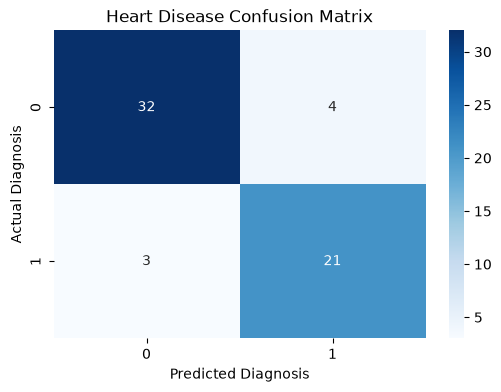

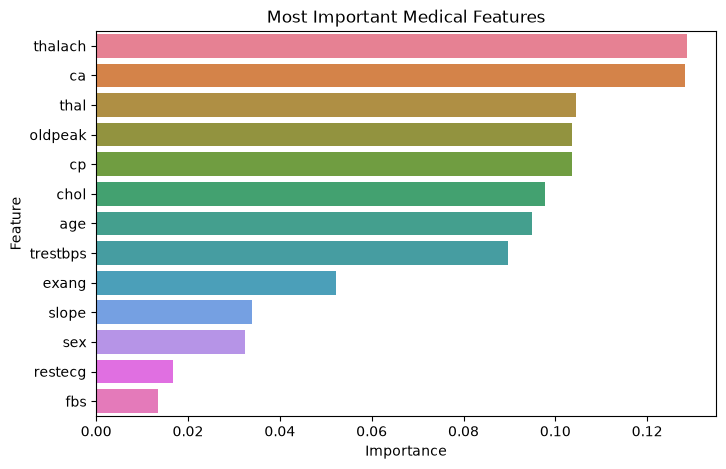

In [8]:
# Install visualization libraries
%pip install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Plot the Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, cmap='Blues', fmt='g')
plt.title('Heart Disease Confusion Matrix')
plt.xlabel('Predicted Diagnosis')
plt.ylabel('Actual Diagnosis')
plt.show()

# Plot Feature Importances
importances = model.feature_importances_
importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=importance_df, hue='Feature', legend=False)
plt.title('Most Important Medical Features')
plt.show()